Лабораторная работа №1

Тимошенко Софья Антоновна

ИНФА-231

Решение варианта №12

Среди учащихся, родители которых имеют образование high school, средний балл по математике у учеников со стандартным питанием (standard lunch) выше, чем у учеников с льготным питанием (free/reduced lunch).


In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("Всё готово к работе!")

Всё готово к работе!


In [7]:
url = "https://raw.githubusercontent.com/NadavKiani/Students-Performance-in-Exams/master/StudentsPerformance.csv"

df_raw = pd.read_csv(url)

print("Данные загружены!")
print("Размер таблицы:", df_raw.shape)

display(df_raw.head())

Данные загружены!
Размер таблицы: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [8]:
print("Первые 5 строк таблицы:")
display(df_raw.head())

print("Размер таблицы:")
print(df_raw.shape)

print("Информация о столбцах:")
df_raw.info()

print("Количество пропусков:")
print(df_raw.isna().sum())

print("Количество дубликатов:")
print(df_raw.duplicated().sum())

print("Числовая статистика:")
display(df_raw.describe())

Первые 5 строк таблицы:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


Размер таблицы:
(1000, 8)
Информация о столбцах:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB
Количество пропусков:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
readi

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


Проверка баллов в диапозоне

In [9]:

score_columns = ["math score", "reading score", "writing score"]

for col in score_columns:
    print(f"\n{col}:")
    print("Минимум:", df_raw[col].min())
    print("Максимум:", df_raw[col].max())
    print("Все значения в диапазоне 0–100:",
          df_raw[col].between(0, 100).all())


math score:
Минимум: 0
Максимум: 100
Все значения в диапазоне 0–100: True

reading score:
Минимум: 17
Максимум: 100
Все значения в диапазоне 0–100: True

writing score:
Минимум: 10
Максимум: 100
Все значения в диапазоне 0–100: True


Обработка пропусков

In [10]:
df_clean = df_raw.copy()

print("Исходный размер:", df_raw.shape)
print("Размер копии:", df_clean.shape)
print("Пропуски до обработки:")
print(df_clean.isna().sum())

Исходный размер: (1000, 8)
Размер копии: (1000, 8)
Пропуски до обработки:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [11]:
for col in ["math score", "reading score", "writing score"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mean())

print("Пропуски после обработки:")
print(df_clean.isna().sum())

Пропуски после обработки:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


Поиск и обработка выбросов методом Z-score

In [12]:

score_columns = ["math score", "reading score", "writing score"]

for col in score_columns:
    z_scores = stats.zscore(df_clean[col])
    outliers = (abs(z_scores) > 3)

    print(f"\nСтолбец: {col}")
    print("Количество потенциальных выбросов:", outliers.sum())


Столбец: math score
Количество потенциальных выбросов: 4

Столбец: reading score
Количество потенциальных выбросов: 4

Столбец: writing score
Количество потенциальных выбросов: 4


Ученики, у которых родителей уровень образования high school

In [13]:

df_variant = df_clean[
    df_clean["parental level of education"] == "high school"
].copy()

print("Количество учеников в варианте 12:", len(df_variant))
print("\nПроверка фильтра:")
display(df_variant["parental level of education"].value_counts())

print("\nПервые 5 строк отфильтрованной таблицы:")
display(df_variant.head())

Количество учеников в варианте 12: 196

Проверка фильтра:


,count
parental level of education,
high school,196



Первые 5 строк отфильтрованной таблицы:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
8,male,group D,high school,free/reduced,completed,64,64,67
9,female,group B,high school,free/reduced,none,38,60,50
12,female,group B,high school,standard,none,65,81,73
16,male,group C,high school,standard,none,88,89,86
20,male,group D,high school,standard,none,66,69,63


Статистика для Math, Reaging


In [14]:

metrics = ["math score", "reading score"]

for col in metrics:
    print(f"\n--- {col} ---")
    print("Количество:", df_variant[col].count())
    print("Среднее:", round(df_variant[col].mean(), 2))
    print("Медиана:", round(df_variant[col].median(), 2))
    print("Стандартное отклонение:", round(df_variant[col].std(), 2))
    print("Минимум:", df_variant[col].min())
    print("Максимум:", df_variant[col].max())
    print("Q1:", df_variant[col].quantile(0.25))
    print("Q3:", df_variant[col].quantile(0.75))
    print("IQR:", df_variant[col].quantile(0.75) - df_variant[col].quantile(0.25))


--- math score ---
Количество: 196
Среднее: 62.14
Медиана: 63.0
Стандартное отклонение: 14.54
Минимум: 8
Максимум: 99
Q1: 53.75
Q3: 72.0
IQR: 18.25

--- reading score ---
Количество: 196
Среднее: 64.7
Медиана: 66.0
Стандартное отклонение: 14.13
Минимум: 24
Максимум: 99
Q1: 54.0
Q3: 74.25
IQR: 20.25


Строим графики

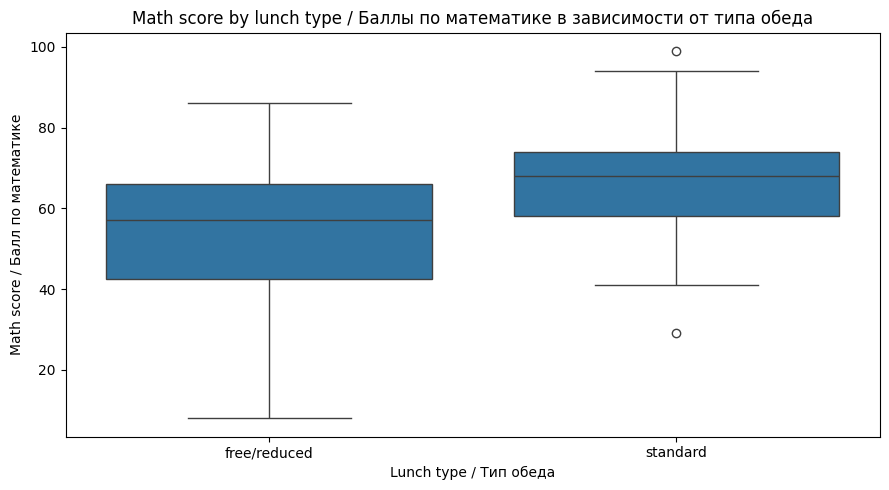

In [15]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_variant,
    x="lunch",
    y="math score"
)

plt.title(
    "Math score by lunch type / "
    "Баллы по математике в зависимости от типа обеда"
)

plt.xlabel(
    "Lunch type / Тип обеда"
)

plt.ylabel(
    "Math score / Балл по математике"
)

plt.tight_layout()
plt.show()

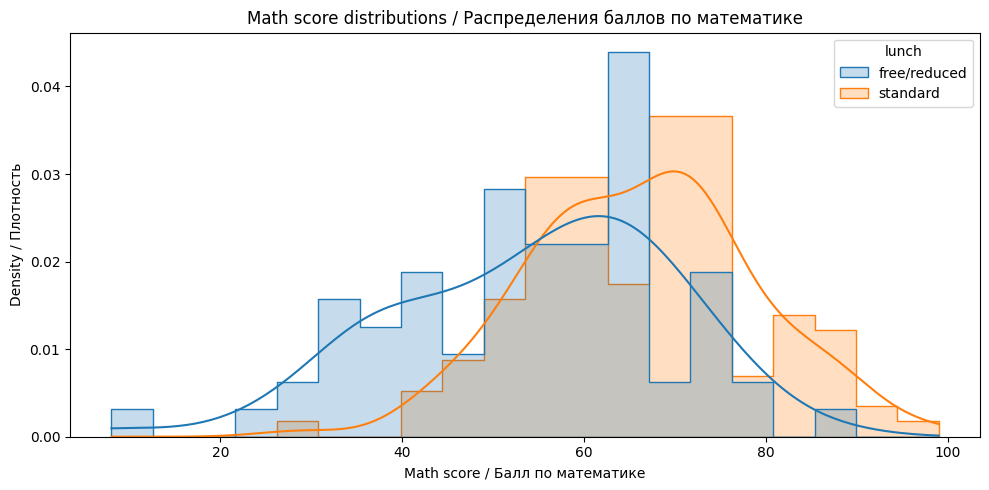

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_variant,
    x="math score",
    hue="lunch",
    bins=20,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title(
    "Math score distributions / "
    "Распределения баллов по математике"
)

plt.xlabel("Math score / Балл по математике")
plt.ylabel("Density / Плотность")

plt.tight_layout()
plt.show()

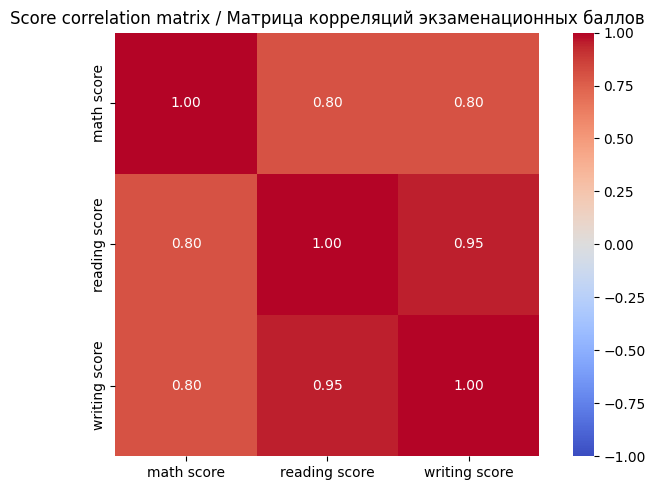

,math score,reading score,writing score
math score,1.000,0.802,0.798
reading score,0.802,1.000,0.947
writing score,0.798,0.947,1.000


In [17]:

# 3. CORRELATION HEATMAP

score_cols = ["math score", "reading score", "writing score"]

corr_matrix = df_variant[score_cols].corr(method="pearson")

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    square=True,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.title(
    "Score correlation matrix / "
    "Матрица корреляций экзаменационных баллов"
)

plt.tight_layout()
plt.show()

display(corr_matrix.round(3))

Формулировка гипотез и выбор критерия

Обозначим средний балл по математике в двух группах:

μs — средний балл учеников со стандартным питанием;

μf — средний балл учеников с льготным питанием.

Тогда гипотезы будут такими:

H0:μs≤μf

H1:μs>μf
	​

Уровень значимости: α=0.05

In [18]:

# Оставляем учеников, родители которых имеют образование high school
df_hypothesis = df_variant[
    df_variant["parental level of education"].eq("high school")
].copy()

print("Проверка образования родителей:")
print(df_hypothesis["parental level of education"].value_counts())

# Две группы по типу питания
standard = df_hypothesis.loc[
    df_hypothesis["lunch"].eq("standard"),
    "math score"
].dropna().astype(float)

free_reduced = df_hypothesis.loc[
    df_hypothesis["lunch"].eq("free/reduced"),
    "math score"
].dropna().astype(float)

print("Количество учеников:")
print("standard:", len(standard))
print("free/reduced:", len(free_reduced))

print("\nСредний балл по математике:")
print(f"standard: {standard.mean():.2f}")
print(f"free/reduced: {free_reduced.mean():.2f}")

difference = standard.mean() - free_reduced.mean()
print(f"Разница средних: {difference:.2f}")

result = stats.ttest_ind(
    standard,
    free_reduced,
    equal_var=False,
    alternative="greater"
)

t_stat = result.statistic
p_value = result.pvalue
alpha = 0.05

print(f"\nt = {t_stat:.4f}")
print(f"p-value = {p_value:.8g}")
print(f"alpha = {alpha}")

if p_value < alpha:
    print("\nОтклоняем H0 в пользу H1.")
    print(
        "Есть статистические основания считать, что "
        "средний балл группы standard выше."
    )
else:
    print("\nНет достаточных оснований отклонить H0.")
    print(
        "Гипотеза о более высоком среднем балле группы "
        "standard статистически не подтверждена."
    )

Проверка образования родителей:
parental level of education
high school    196
Name: count, dtype: int64
Количество учеников:
standard: 126
free/reduced: 70

Средний балл по математике:
standard: 66.37
free/reduced: 54.51
Разница средних: 11.86

t = 5.5977
p-value = 6.9597056e-08
alpha = 0.05

Отклоняем H0 в пользу H1.
Есть статистические основания считать, что средний балл группы standard выше.


### Результаты проверки гипотезы

В исследовании сравнивались результаты по математике учащихся, родители которых имеют образование high school. Средний балл учеников со стандартным питанием (standard lunch) составил 66,37, а учеников с льготным питанием (free/reduced lunch) — 54,51. Разница средних значений составила 11,86 балла.

Получено значение t = 5,5977 и p-value ≈ 6,96 × 10⁻⁸. Поскольку p-value меньше уровня значимости 0,05, нулевая гипотеза отвергается в пользу альтернативной.

Педагогический вывод: таким образом, полученные данные дают статистические основания утверждать, что среди рассматриваемых учащихся средний балл по математике у учеников со стандартным питанием выше, чем у учеников с льготным питанием. При этом результат не доказывает, что тип питания является причиной различия в успеваемости.


Дополнительное задание

In [22]:
# Подготовка CSV для BigQuery
bq_export = df_clean.rename(columns={
    "race/ethnicity": "race_ethnicity",
    "parental level of education": "parental_education",
    "test preparation course": "test_preparation",
    "math score": "math_score",
    "reading score": "reading_score",
    "writing score": "writing_score",
}).copy()

BQ_CSV = "students_performance_lab01_clean.csv"

bq_export.to_csv(BQ_CSV, index=False)

print("Файл для BigQuery:", BQ_CSV)
print("Строк:", len(bq_export))
print("Столбцов:", len(bq_export.columns))



Файл для BigQuery: students_performance_lab01_clean.csv
Строк: 1000
Столбцов: 8
